Notebook used to test methods to standardize data across DEMs and across storms. The methods are:
- Calculate MWL per timestep (avg across transect) & subtract
- Calculate MWL per transect over time & subtract
- Look up MWL from tide guage and subtract

Datasets being used in this analysis: 
- 1702827001820 (Dec 17, 2023 10:30 AM | 239 frames of data (frame 5 is technically null))
- add a later epoch in nor'easter
- grab from recent nor'easter

Most recent edits: BG 10/7/2026

In [1]:
import matplotlib.pyplot as plt
import numpy as np
#np.long = int 
import pandas as pd
import tensorflow as tf
import os
import glob
import mat73
import gc
from scipy.io import loadmat

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
#from tensorflow.keras.datasets import fashion_mnist (fake data)
from tensorflow.keras.models import Model
from PIL import Image


import keras
from matplotlib.animation import FuncAnimation
import seaborn as sns
from scipy import signal
import re

2026-10-20 09:28:06.445433: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# paths  /Volumes/kanarde/MasonBEAST
modelsavepath=r'/Volumes/kanarde/MasonBEAST/data/trained_models/testing_standardization/'
savepath=r'/Volumes/kanarde/MasonBEAST/data/testingtime1/testing_standardization/'
transect_1702827001820_path=r'/Volumes/kanarde/MasonBEAST/data/DEMs/1702827001820/Transects/alongshore_transects.mat'

figpath1820=os.path.join(savepath,'1702827001820/Figures/')

Starting with the 1702827001820 dataset...

In [3]:
# Load Data
def loadNprep(training_datapath):
    # This function takes a path to a .mat file of transects in the form of a matrices (cross-shore pts x timesteps) 
    # imbedded in a larger structure (generated from ptcld2DEM2transects_process.m) and outputs dataframes of 
    # the transects
    raw_mat=loadmat(training_datapath)
    train_struct=raw_mat['tran_struct']

    all_trans=[]
    names=[]

    for elem in train_struct.ravel():
        name=elem['name'].item()
        data_matrix=elem['data']

        temp_df=pd.DataFrame(data_matrix)
        temp_df['name']=name

        all_trans.append(temp_df)
        names.append(name)

    train_trans_df=pd.concat(all_trans,axis=0,keys=names, names=['transect_name','original_index'])
    train_ds1=train_trans_df.drop(columns=['name'])
    print("Dataset 1 Shape:", train_ds1.shape)

    return train_ds1

In [4]:
def sort_transects(ds,descending=True):
    transects={transect_name:group.droplevel('transect_name') for transect_name,group in ds.groupby(level='transect_name')}
    print(f"{len(transects)} transects in given ds")
    import re
    # sort chronologicallly
    def extract_y_loc(name):
        match=re.search(r'y([-+]?\d+\.?\d*)',name)
        if match:
            return float(match.group(1))
        return 0
    sorted_transect_keys=sorted(transects.keys(),key=extract_y_loc,reverse=descending)
    sorted_transects={k:transects[k] for k in sorted_transect_keys}
    return sorted_transects

In [5]:
tran1702827001820=loadNprep(transect_1702827001820_path) # load
sorted_1820_dict=sort_transects(tran1702827001820,descending=True) #sort
sorted_1820=pd.concat(sorted_1820_dict.values(), keys=sorted_1820_dict.keys()) # dataframe

Dataset 1 Shape: (23693, 239)
43 transects in given ds


Grab transects through the DEM to test standardization teqniques

In [6]:
tran_7_3=sorted_1820.loc["transect_y7.3"]
tran_9_3=sorted_1820.loc["transect_y9.3"]
tran_neg4=sorted_1820.loc["transect_y-4"]
tran_21_3=sorted_1820.loc["transect_y21.3"]

print((tran_21_3.shape))

(551, 239)


In [7]:
def beach_elev(
    transect_matrix,
    region_start=100,
    region_end=200,
    window=120,
    quantile=0.1
):
    """
    Calculate a dynamic beach-face elevation line.

    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions
        Columns = timesteps

    region_start : int
        Starting cross-shore index of the beach-face region.

    region_end : int
        Ending cross-shore index of the beach-face region.

    window : int
        Number of previous frames used to calculate the beach face.
        120 frames = 1 minute if the data are sampled at 2 frames/second.

    quantile : float
        Quantile used to identify the lower-elevation values.
        0.1 = lowest 10%.

    Returns
    -------
    beachface : pandas.DataFrame
        Rows = cross-shore positions 100–200
        Columns = timesteps

        Each column is the dynamic beach-face profile for that timestep.
    """

    # Select beach-face region
    beach_region = transect_matrix.iloc[
        region_start:region_end + 1, :
    ].copy()

    # Make sure values are numeric
    beach_region = beach_region.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Output DataFrame
    beachface = pd.DataFrame(
        index=beach_region.index,
        columns=transect_matrix.columns,
        dtype=float
    )

    # Loop through each timestep
    for i, t in enumerate(transect_matrix.columns):

        # Previous 120 frames, including current frame
        start = max(0, i - window + 1)

        time_window = beach_region.iloc[:, start:i + 1]

        # Calculate low-elevation value at each cross-shore position
        beachface[t] = time_window.quantile(
            quantile,
            axis=1
        )

    return beachface

In [8]:
def runup_extent(transect_matrix, beachface, threshold=0.03):
    """
    Calculate runup extent for each timestep using a dynamic,
    spatially varying beach-face elevation.

    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions
        Columns = timesteps.

    beachface : pandas.DataFrame
        Dynamic beach-face elevations.
        Rows = cross-shore positions
        Columns = timesteps.

    threshold : float
        Elevation above beach face used to identify water/runup.
        Default = 0.03 m (3 cm).

    Returns
    -------
    runup : pandas.Series
        Maximum cross-shore position where the transect is
        more than threshold above the beach face.
    """

    runup = pd.Series(
        index=transect_matrix.columns,
        dtype=float
    )

    # Make sure beachface has the same cross-shore index
    beachface = beachface.reindex(
        index=transect_matrix.index,
        columns=transect_matrix.columns
    )

    for t in transect_matrix.columns:

        z = pd.to_numeric(
            transect_matrix[t],
            errors="coerce"
        )

        bf = pd.to_numeric(
            beachface[t],
            errors="coerce"
        )

        # Water/runup is elevation > beach face + threshold
        above_beach = (
            (z - bf) > threshold
        )

        # Only use locations where both are valid
        valid = (
            above_beach &
            z.notna() &
            bf.notna()
        )

        if valid.any():
            runup.loc[t] = valid[valid].index.max()
        else:
            runup.loc[t] = np.nan

    return runup

In [9]:
def runup_extent(transect_matrix, beachface, threshold=0.03, min_consecutive=1):
    """
    Calculate runup extent for each timestep using a dynamic,
    spatially varying beach-face elevation.
   
    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions (Index 0 assumed offshore/ocean).
        Columns = timesteps.
    beachface : pandas.DataFrame
        Dynamic beach-face elevations.
        Rows = cross-shore positions
        Columns = timesteps.
    threshold : float
        Elevation above beach face used to identify water/runup.
        Default = 0.03 m (3 cm).
    min_consecutive : int, optional
        Minimum number of consecutive pixels required above threshold
        to be considered valid runup (default = 1).

    Returns
    -------
    runup : pandas.Series
        Maximum cross-shore position where the transect is
        continuously more than threshold above the beach face.
    """
    runup = pd.Series(
        index=transect_matrix.columns,
        dtype=float
    )

    # Make sure beachface has the same cross-shore index
    beachface = beachface.reindex(
        index=transect_matrix.index,
        columns=transect_matrix.columns
    )

    for t in transect_matrix.columns:

        z = pd.to_numeric(
            transect_matrix[t],
            errors="coerce"
        )

        bf = pd.to_numeric(
            beachface[t],
            errors="coerce"
        )

        # Water/runup is elevation > beach face + threshold
        above_beach = (
            (z - bf) > threshold
        )

        # Only use locations where both are valid
        valid = (
            above_beach &
            z.notna() &
            bf.notna()
        )

        # 1. Enforce continuity starting from offshore (index 0)
        # cumprod() stays True (1) only until the first False (0), then stays False
        continuous_valid = valid.cumprod().astype(bool)

        # 2. Optional: Filter out short continuous runs smaller than min_consecutive
        if min_consecutive > 1 and continuous_valid.sum() < min_consecutive:
            continuous_valid[:] = False

        if continuous_valid.any():
            runup.loc[t] = continuous_valid[continuous_valid].index.max()
        else:
            runup.loc[t] = np.nan

    return runup

In [10]:
def runup_extent(transect_matrix, beachface, threshold=0.03, min_consecutive=3):
    """
    Calculate runup extent for each timestep requiring water to be
    continuously above threshold across a minimum block of points.
   
    Parameters
    ----------
    transect_matrix : pandas.DataFrame
        Rows = cross-shore positions, Columns = timesteps.
    beachface : pandas.DataFrame
        Dynamic beach-face elevations.
    threshold : float
        Elevation above beach face used to identify water (default = 0.03 m).
    min_consecutive : int
        Minimum consecutive spatial points above threshold required
        to qualify as valid runup (default = 3 points). Filters single-pixel noise.

    Returns
    -------
    runup : pandas.Series
        Cross-shore runup position for each timestep.
    """
    runup = pd.Series(
        index=transect_matrix.columns,
        dtype=float
    )

    # Reindex beachface to match transect_matrix
    beachface = beachface.reindex(
        index=transect_matrix.index,
        columns=transect_matrix.columns
    )

    for t in transect_matrix.columns:
        z = pd.to_numeric(transect_matrix[t], errors="coerce")
        bf = pd.to_numeric(beachface[t], errors="coerce")

        # 1. Flag points exceeding threshold
        valid = ((z - bf) > threshold) & z.notna() & bf.notna()

        if not valid.any():
            runup.loc[t] = np.nan
            continue

        # 2. Identify contiguous blocks of True values
        # Assign a new ID whenever value changes (True <-> False)
        blocks = (valid != valid.shift()).cumsum()

        # Count total size of each contiguous block of True points
        block_sizes = valid.groupby(blocks).transform("sum")

        # Keep points that belong to a block of size >= min_consecutive
        continuous_valid = valid & (block_sizes >= min_consecutive)

        # 3. Extract boundary index
        if continuous_valid.any():
            # Assumes index increases landward (0 = offshore, max_index = land):
            runup.loc[t] = continuous_valid[continuous_valid].index.max()
           
            # Note: If index 0 is Land and max_index is Offshore, use .min() instead:
            # runup.loc[t] = continuous_valid[continuous_valid].index.min()
        else:
            runup.loc[t] = np.nan

    return runup

In [11]:
beachface_7_3=beach_elev(tran_7_3,100,200,window=120)
runup_7_3=runup_extent(tran_7_3,beachface_7_3,threshold=0.03, min_consecutive=3)

**Method 1: Calculate the MWL (spatial avg per timestep per transect) and subtract)**

In [12]:
def MWL_per_time(transect_matrix, runup_extent):

    MWL_tstep = []

    displacement = pd.DataFrame(
        index=transect_matrix.index,
        columns=transect_matrix.columns,
        dtype=float
    )

    # Cross-shore coordinates
    x = pd.to_numeric(
        transect_matrix.index,
        errors="coerce"
    ).to_numpy(dtype=float)

    for t in transect_matrix.columns:

        # Runup location for this timestep
        r = runup_extent.loc[t]

        # --------------------------------------------------
        # No valid runup
        # --------------------------------------------------

        if pd.isna(r):
            MWL_tstep.append(np.nan)
            displacement[t] = np.nan
            continue

        r = float(r)

        # --------------------------------------------------
        # Find nearest cross-shore row to runup
        # --------------------------------------------------

        valid_x = np.isfinite(x)

        if not valid_x.any():
            MWL_tstep.append(np.nan)
            displacement[t] = np.nan
            continue

        valid_positions = np.where(valid_x)[0]

        nearest_position = valid_positions[
            np.argmin(
                np.abs(x[valid_positions] - r)
            )
        ]

        # --------------------------------------------------
        # Get transect elevations from runup onward
        # --------------------------------------------------

        aeta = pd.to_numeric(
            transect_matrix.iloc[
                nearest_position:,
                transect_matrix.columns.get_loc(t)
            ],
            errors="coerce"
        )

        # --------------------------------------------------
        # Calculate MWL
        # --------------------------------------------------

        MWL = aeta.mean()

        MWL_tstep.append(MWL)

        # --------------------------------------------------
        # Calculate net displacement
        # --------------------------------------------------

        displacement[t] = (
            pd.to_numeric(
                transect_matrix[t],
                errors="coerce"
            ) - MWL
        )

    # ------------------------------------------------------
    # Convert MWL to Series
    # ------------------------------------------------------

    MWL_tstep = pd.Series(
        MWL_tstep,
        index=transect_matrix.columns,
        dtype=float
    )

    return MWL_tstep, displacement

In [13]:
MWL_7_3,displacement_7_3=MWL_per_time(tran_7_3,runup_7_3)

In [14]:
print(tran_7_3.shape)
print(displacement_7_3.shape)
print(beachface_7_3.shape)

(551, 239)
(551, 239)
(101, 239)


In [15]:
def plot_net_displacement(
    transect_matrix,
    net_displacement,
    MWL,
    runup_extent,
    beach_face,
    interval=100,
    save_path=None,
):
    """
    Animate:
        Top:    transect, MWL line, dynamic beach face, runup point (max elevation capped at 8m)
        Bottom: net displacement (always plotted; values LEFT of runup masked as NaN when available)

    Transect orientation:
        rows    = cross-shore positions
        columns = timesteps
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.animation import FuncAnimation

    # ---------------------------------------------------------
    # 1. Clean, numericize, and sort cross-shore coordinates
    # ---------------------------------------------------------
    transect_matrix = transect_matrix.copy()
    transect_matrix.index = pd.to_numeric(transect_matrix.index, errors="coerce")
    transect_matrix = transect_matrix.sort_index()

    x = transect_matrix.index.to_numpy(dtype=float)
    timesteps = transect_matrix.columns

    # Helper function to convert scalar/Series/DataFrame inputs cleanly
    def _to_series(val, t_cols):
        if isinstance(val, (int, float, np.number)):
            return pd.Series(float(val), index=t_cols)
        elif isinstance(val, pd.Series):
            return val.reindex(t_cols)
        elif isinstance(val, pd.DataFrame):
            return val.iloc[0].reindex(t_cols)
        else:
            return pd.Series(val, index=t_cols)

    mwl_series = _to_series(MWL, timesteps)
    runup_series = _to_series(runup_extent, timesteps)

    # ---------------------------------------------------------
    # 2. Reindex inputs to match sorted transect
    # ---------------------------------------------------------
    net_displacement = net_displacement.reindex(
        index=transect_matrix.index,
        columns=timesteps
    )

    beach_face = beach_face.copy()
    beach_face.index = pd.to_numeric(beach_face.index, errors="coerce")
    beach_face = beach_face.sort_index().reindex(columns=timesteps)
    beachface_x = beach_face.index.to_numpy(dtype=float)

    # ---------------------------------------------------------
    # 3. Y-Limits Pre-calculation
    # ---------------------------------------------------------
    # Top plot min elevation calculation
    all_elev = transect_matrix.to_numpy(dtype=float)
    all_beach = beach_face.to_numpy(dtype=float)
    all_mwl = pd.to_numeric(mwl_series, errors="coerce").to_numpy(dtype=float)

    valid_elev_all = all_elev[np.isfinite(all_elev)]
    valid_beach_all = all_beach[np.isfinite(all_beach)]
    valid_mwl_all = all_mwl[np.isfinite(all_mwl)]

    combined_elev = np.concatenate([
        valid_elev_all if len(valid_elev_all) > 0 else [0],
        valid_beach_all if len(valid_beach_all) > 0 else [0],
        valid_mwl_all if len(valid_mwl_all) > 0 else [0]
    ])
    y1_min = np.nanmin(combined_elev)
    y1_pad = (8.0 - y1_min) * 0.05 if 8.0 > y1_min else 0.5
    y1_bottom = y1_min - y1_pad

    # Bottom plot (displacement) y-limits calculated globally across all timesteps
    disp_matrix = net_displacement.to_numpy(dtype=float).copy()
    disp_masked_matrix = disp_matrix.copy()

    for col_idx, t in enumerate(timesteps):
        rx = runup_series.loc[t]
        if pd.notna(rx):
            disp_masked_matrix[x < float(rx), col_idx] = np.nan

    valid_disp_all = disp_masked_matrix[np.isfinite(disp_masked_matrix)]
    if len(valid_disp_all) == 0:
        valid_disp_all = disp_matrix[np.isfinite(disp_matrix)]

    if len(valid_disp_all) > 0:
        y2_min, y2_max = np.nanmin(valid_disp_all), np.nanmax(valid_disp_all)
        y2_pad = (y2_max - y2_min) * 0.1 if y2_max != y2_min else 0.1
    else:
        y2_min, y2_max, y2_pad = -0.1, 0.1, 0.05

    # ---------------------------------------------------------
    # 4. Figure & Axes Setup
    # ---------------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(11, 8),
        sharex=True
    )

    # Set top plot max elevation strictly to 8m
    ax1.set_ylim(bottom=y1_bottom, top=8.0)
    ax2.set_ylim(y2_min - y2_pad, y2_max + y2_pad)

    # =========================================================
    # FIRST FRAME INITIALIZATION
    # =========================================================
    t0 = timesteps[0]

    # Transect
    elev0 = pd.to_numeric(
        transect_matrix[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    transect_line, = ax1.plot(
        x,
        elev0,
        linewidth=2,
        label="Transect"
    )

    # MWL
    mwl0 = mwl_series.loc[t0]
    mwl0_val = float(mwl0) if pd.notna(mwl0) else np.nan

    mwl_line = ax1.axhline(
        mwl0_val,
        linestyle="--",
        linewidth=2,
        label="MWL"
    )

    # Dynamic beach face
    beachface0 = pd.to_numeric(
        beach_face[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_beach0 = (
        np.isfinite(beachface_x) &
        np.isfinite(beachface0)
    )

    beachface_line, = ax1.plot(
        beachface_x[valid_beach0],
        beachface0[valid_beach0],
        color="tan",
        linewidth=3,
        label="Beach face"
    )

    # Runup point
    runup_x0 = runup_series.loc[t0]

    if pd.notna(runup_x0):
        runup_x0 = float(runup_x0)
        valid_elev0 = np.isfinite(x) & np.isfinite(elev0)

        if valid_elev0.sum() >= 2:
            runup_y0 = np.interp(
                runup_x0,
                x[valid_elev0],
                elev0[valid_elev0]
            )
        else:
            runup_y0 = np.nan
    else:
        runup_x0 = np.nan
        runup_y0 = np.nan

    runup_point, = ax1.plot(
        [runup_x0],
        [runup_y0],
        marker="o",
        markersize=10,
        linestyle="None",
        color="pink",
        label="Runup"
    )

    ax1.set_ylabel("Elevation")
    ax1.set_title(f"Transect — timestep {t0}")
    ax1.legend()
    ax1.grid(True)

    # Net displacement (First Frame)
    disp0 = pd.to_numeric(
        net_displacement[t0],
        errors="coerce"
    ).to_numpy(dtype=float)

    disp_plot0 = disp0.copy()
    if pd.notna(runup_x0):
        disp_plot0[x < runup_x0] = np.nan

    displacement_line, = ax2.plot(
        x,
        disp_plot0,
        color="purple",
        linewidth=2.5,
        label="Net displacement"
    )

    ax2.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax2.set_xlabel("Cross-shore position")
    ax2.set_ylabel("Net displacement")
    ax2.legend()
    ax2.grid(True)

    # =========================================================
    # UPDATE FUNCTION
    # =========================================================
    def update(frame):
        t = timesteps[frame]

        # Transect
        elev = pd.to_numeric(
            transect_matrix[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        transect_line.set_data(x, elev)

        # MWL
        mwl_val = mwl_series.loc[t]
        if pd.notna(mwl_val):
            mwl_val = float(mwl_val)
            mwl_line.set_ydata([mwl_val, mwl_val])
        else:
            mwl_line.set_ydata([np.nan, np.nan])

        # Dynamic beach face
        beachface = pd.to_numeric(
            beach_face[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        valid_beach = np.isfinite(beachface_x) & np.isfinite(beachface)
        beachface_line.set_data(
            beachface_x[valid_beach],
            beachface[valid_beach]
        )

        # Runup point
        runup_x = runup_series.loc[t]

        if pd.notna(runup_x):
            runup_x = float(runup_x)
            valid_elev = np.isfinite(x) & np.isfinite(elev)

            if valid_elev.sum() >= 2:
                runup_y = np.interp(
                    runup_x,
                    x[valid_elev],
                    elev[valid_elev]
                )
                runup_point.set_data([runup_x], [runup_y])
            else:
                runup_point.set_data([runup_x], [np.nan])
        else:
            runup_point.set_data([np.nan], [np.nan])

        # Net displacement
        disp = pd.to_numeric(
            net_displacement[t],
            errors="coerce"
        ).to_numpy(dtype=float)

        disp_plot = disp.copy()
        if pd.notna(runup_x):
            # NaN out values left of runup in cross-shore
            disp_plot[x < runup_x] = np.nan

        displacement_line.set_data(x, disp_plot)

        ax1.set_title(f"Transect — timestep {t}")

        return (
            transect_line,
            displacement_line,
            mwl_line,
            beachface_line,
            runup_point,
        )

    # =========================================================
    # CREATE ANIMATION
    # =========================================================
    anim = FuncAnimation(
        fig,
        update,
        frames=len(timesteps),
        interval=interval,
        blit=False
    )

    # Save logic
    if save_path is not None:
        if save_path.lower().endswith(".gif"):
            anim.save(
                save_path,
                writer="pillow",
                fps=1000 / interval,
                dpi=200
            )
        else:
            anim.save(
                save_path,
                writer="ffmpeg",
                fps=1000 / interval,
                dpi=200
            )

        print(f"Saved animation to: {save_path}")

    plt.tight_layout()

    return anim

In [16]:
water_depth=tran_7_3.iloc[:,100:200]-beachface_7_3
depth_thresh=0.02
is_wet=(water_depth>depth_thresh).to_numpy()
runup_index_local=np.argmax(is_wet,axis=1)
runup_index=runup_index_local+100

In [111]:
print(runup_index)
cross_shore=np.arange(0,551)
runup_x=cross_shore[runup_index]

[100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 226 200 200 224 200 200 200 200
 200 200 200 200 221 221 221 221 220 219 220 220 218 218 218 217 202 203
 217 203 217 216 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200 200 200 200 200 200 200 204 204 207 207 207 207 207 207 206 206 206
 205 205 205 204 204 201 200 204 203 200 200 200 200 200 200 200 200 201
 201 201 201 201 201 201 201 200 200 200 200 200 200 200 200 200 200 200
 200 200 200 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100
 100 100 100 100 100 100 100 100 100 100 100 100 10

In [114]:
print(runup_x.shape)

(551,)


In [116]:
water_depth = tran_7_3.iloc[:, 100:200].sub(beachface_7_3, axis=1) 
# 2. Boolean matrix of wet cells (shape: 239 timesteps x 100 cross-shore points)
is_wet = (water_depth > 0.02).to_numpy() 
# 3. Find first wet column per timestep along axis=1 (returns length 239) 
local_runup_index = np.argmax(is_wet, axis=1) 
# 4. Create a pandas Series aligned with tran_7_3's timesteps 
runup_index = pd.Series(100 + local_runup_index, index=tran_7_3.index) #
#Verify length matches timesteps (should print 239) 
print(f"Runup series length: {len(runup_index)}")

Runup series length: 551


Saved animation to: /Users/bagaenzl/Desktop/test/vid.gif


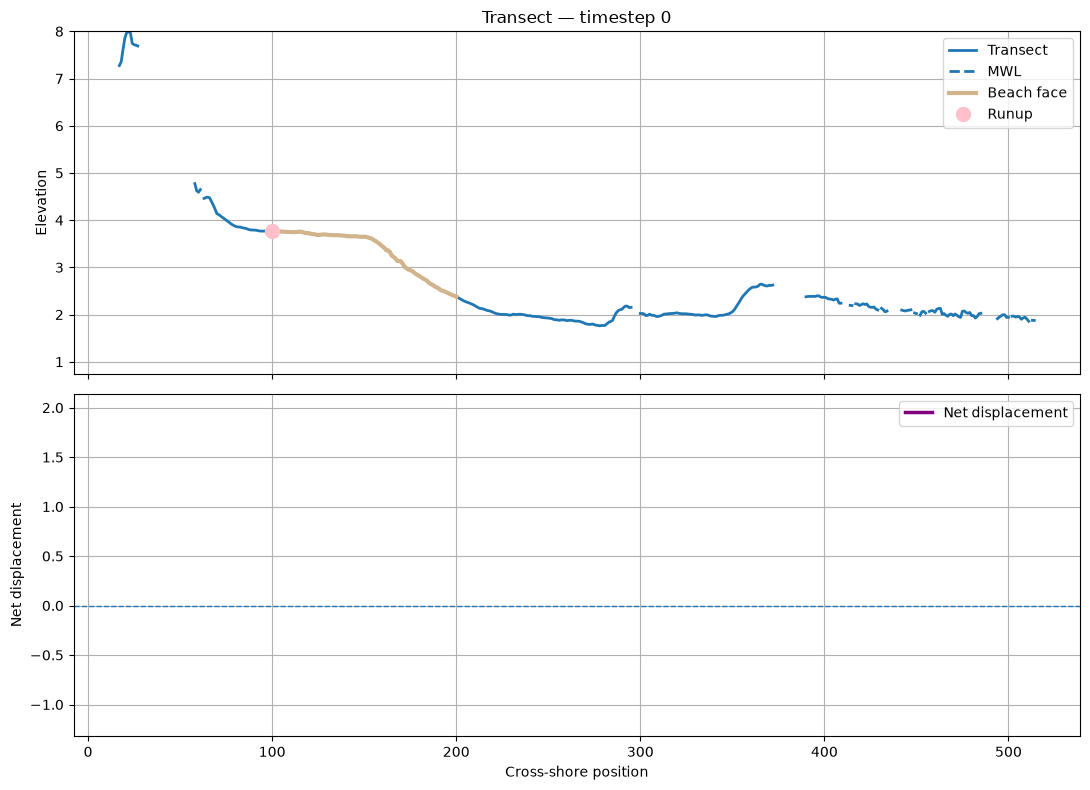

In [117]:
figpath=os.path.join(savepath,'MWL_per_tstep/')
os.makedirs(figpath, exist_ok=True)
figpath=os.path.join(figpath,'anim.gif')
figpath=r'/Users/bagaenzl/Desktop/test/vid.gif'
plot_net_displacement(transect_matrix=tran_7_3,
                          net_displacement=displacement_7_3,
                          MWL=MWL_7_3,
                          runup_extent=runup_index,
                          beach_face=beachface_7_3,
                          interval=500,save_path=figpath
                          )

In [98]:
def plot_elevation_timestack(
    transect,
    runup,
    cmap='Blues_r',       # Bathymetry/elevation friendly colormaps: 'terrain', 'Blues_r', 'viridis', 'YlGnBu_r'
    origin='upper',        # 'upper' sets t=0 at the top; 'lower' sets t=0 at the bottom
    figsize=(9, 11),
    title='Elevation Timestack — Transect 7_3',
    cbar_label='Elevation / Depth'
):
    """
    Plots a timestack using the elevation values in the transect matrix for color-mapping.
   
    Parameters
    ----------
    transect : 2D array, shape (n_timesteps, n_cross_shore)
        Matrix of elevation/depth values.
    runup : 1D array-like, length n_timesteps
        Cross-shore index location of runup for each timestep.
    cmap : str or Colormap, optional
        Colormap representing elevation/depth values (default: 'terrain').
    origin : {'upper', 'lower'}, optional
        Orientation of timesteps on the Y-axis.
    """
    fig, ax = plt.subplots(figsize=figsize)

    # 1. Render the background using elevation values directly from the matrix
    im = ax.imshow(
        transect,
        aspect='auto',
        origin=origin,
        cmap=cmap,
        vmin=0,
        vmax=4
    )

    # Add colorbar representing elevation/depth
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(cbar_label)

    # 2. Time vector for Y-axis
    timesteps = np.arange(len(runup))

    # 3. Plot runup line: X = cross-shore index, Y = timestep
    ax.plot(
        runup, timesteps,
        color='deeppink',
        linewidth=2,
        label='Runup Extent'
    )

    # Axis Labels & Formatting
    ax.set_xlabel('Cross-Shore Index')
    ax.set_ylabel('Timestep')
    ax.set_title(title)
    ax.legend(loc='upper right')

    plt.tight_layout()
    return fig, ax

In [37]:
print(runup_7_3)

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
       ...  
234    200.0
235    200.0
236    200.0
237    200.0
238    200.0
Length: 239, dtype: float64


In [99]:
# reunup from gradient change
tran_flip=tran_7_3.T
sub_data=tran_flip.iloc[:,100:200] # just looking in beac area
# put values in for NaNs
sub_data_noNan=np.nan_to_num(sub_data,nan=3.35)
grad_x=np.gradient(sub_data_noNan,axis=1)
runup_bound=np.argmin(sub_data_noNan,axis=1)
runup_bound=runup_bound+100

In [100]:
print(runup_bound)

[199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 192 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 192 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 196 191 185 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 198 199 199 199 199 199
 199 199 199 199 199 199 199 199 197 199 199 199 199 199 199 199 198 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 198
 194 191 186 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 197 195 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 194 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
 199 199 199 198 195]


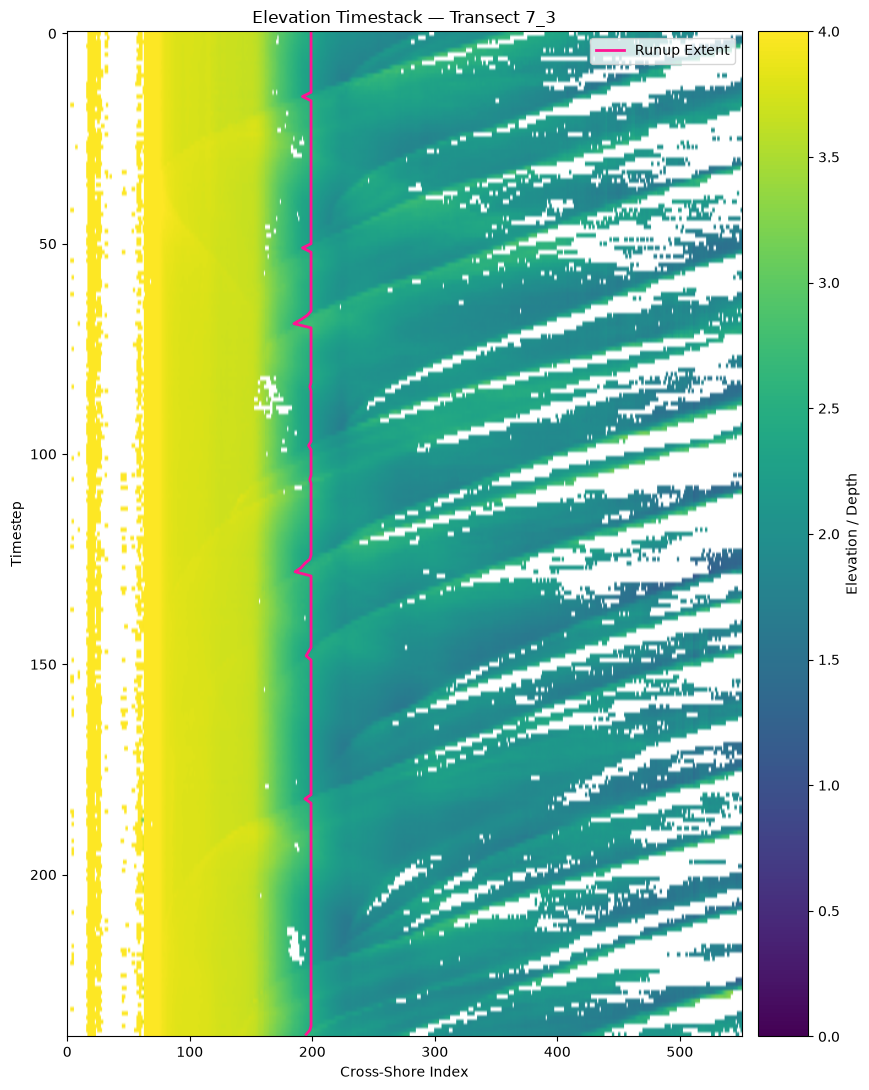

In [101]:
fig,ax=plot_elevation_timestack(transect=tran_7_3.T,runup=runup_bound,cmap='viridis')
plt.show()

**PREP TRAINING DATA**
- this is not including runup exscursion because that doesn't show the model what a breaking wave looks like 
- static point at 200 to just derive surf

Step 1: Static cutoff from all timesteps & demean

In [17]:
def subtract_mean_from_x(
    transect_data, start_x=200, per_timestep=True, apply_to_entire_profile=True
):
    """Calculates the mean elevation using values from start_x to the end of the cross-shore profile,

    and subtracts it out.

    Parameters
    ----------
    transect_data : pd.DataFrame or dict of pd.DataFrame
        Single transect matrix or dictionary of transect matrices.
        (Rows: cross-shore index, Columns: timesteps)
    start_x : int or float, default=200
        The starting cross-shore index (row position or index value) from which to compute the mean.
    per_timestep : bool, default=True
        - If True: Computes a mean for EACH timestep using values from start_x onward,
          and subtracts that timestep's mean from the profile.
        - If False: Computes ONE global scalar mean across all timesteps from start_x onward,
          and subtracts it.
    apply_to_entire_profile : bool, default=True
        - If True: Subtracts the mean from ALL cross-shore points (0 to end).
        - If False: Subtracts the mean ONLY from points from start_x to end (setting 0 to start_x as NaN).

    Returns
    -------
    demeaned_data, calculated_means : (DataFrame/dict, Series/float/dict)
        The mean-subtracted data matrix (or dict) and the calculated mean(s).
    """

    def _process_single(df):
        df_num = df.apply(pd.to_numeric, errors="coerce")

        # Get integer row slice index for start_x
        if start_x in df_num.index:
            row_idx = df_num.index.get_loc(start_x)
        elif isinstance(start_x, (int, np.integer)):
            row_idx = start_x
        else:
            # Find nearest index position if start_x is float
            row_idx = np.argmin(
                np.abs(df_num.index.astype(float) - float(start_x))
            )

        # Slice data from start_x to the end
        sub_df = df_num.iloc[row_idx:, :]

        if per_timestep:
            # Column-wise mean for each timestep using rows start_x to end
            means = sub_df.mean(axis=0)

            if apply_to_entire_profile:
                demeaned = df_num.sub(means, axis=1)
            else:
                demeaned = df_num.copy()
                demeaned.iloc[:row_idx, :] = np.nan
                demeaned.iloc[row_idx:, :] = sub_df.sub(means, axis=1)

        else:
            # Single global mean of all values from start_x to end
            means = np.nanmean(sub_df.to_numpy())

            if apply_to_entire_profile:
                demeaned = df_num - means
            else:
                demeaned = df_num.copy()
                demeaned.iloc[:row_idx, :] = np.nan
                demeaned.iloc[row_idx:, :] = sub_df - means

        return demeaned, means

    # Handle Single DataFrame
    if isinstance(transect_data, pd.DataFrame):
        return _process_single(transect_data)

    # Handle Dictionary of DataFrames
    elif isinstance(transect_data, dict):
        demeaned_dict = {}
        means_dict = {}

        for key, df in transect_data.items():
            demeaned, means = _process_single(df)
            demeaned_dict[key] = demeaned
            means_dict[key] = means

        return demeaned_dict, means_dict

    else:
        raise TypeError(
            "transect_data must be a pandas DataFrame or a dictionary of DataFrames."
        )

In [32]:
disp_dict,means_dict=subtract_mean_from_x(
    sorted_1820_dict, start_x=200, per_timestep=True, apply_to_entire_profile=False
)

In [19]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
import pandas as pd


def animate_displacement(
    disp_df, transect_name="Transect", save_path="displacement.gif", fps=10
):
    """Creates a GIF animation of net displacement over cross-shore position for each timestep.

    Parameters
    ----------
    disp_df : pd.DataFrame
        DataFrame of displacement (Rows: cross-shore index/position, Columns: timesteps)
    transect_name : str, default='Transect'
        Name of the transect to display in the plot title.
    save_path : str, default='displacement.gif'
        Output filename/path for the GIF.
    fps : int, default=10
        Frames per second for the output GIF.
    """
    # 1. Extract cross-shore x coordinates and timestep column names
    x = disp_df.index.astype(float)
    timesteps = disp_df.columns

    # 2. Set up Figure and Axes
    fig, ax = plt.subplots(figsize=(10, 5))

    # Calculate global y-axis bounds to keep the scale fixed across all frames
    all_values = disp_df.to_numpy(dtype=float)
    y_min = np.nanmin(all_values)
    y_max = np.nanmax(all_values)
    margin = (
        0.1 * (y_max - y_min) if (not np.isnan(y_max) and y_max != y_min) else 0.5
    )

    ax.set_xlim(np.nanmin(x), np.nanmax(x))
    ax.set_ylim(y_min - margin, y_max + margin)

    # 3. Initialize line objects
    ax.axhline(
        0, color="gray", linestyle="--", alpha=0.7, label="Zero displacement"
    )
    (line,) = ax.plot([], [], color="purple", lw=2, label="Net displacement")

    ax.set_xlabel("Cross-shore position")
    ax.set_ylabel("Net displacement (m)")
    ax.grid(True)
    ax.legend(loc="upper right")

    # 4. Animation Update Function
    def update(frame):
        t = timesteps[frame]
        y = disp_df[t].to_numpy(dtype=float)

        line.set_data(x, y)
        ax.set_title(f"{transect_name} — Timestep {t}")
        return line,

    # 5. Build Animation
    anim = FuncAnimation(
        fig,
        update,
        frames=len(timesteps),
        interval=1000 / fps,
        blit=False,  # Set blit=False to ensure title updates properly
    )

    # 6. Save as GIF
    writer = PillowWriter(fps=fps)
    anim.save(save_path, writer=writer)
    plt.close(fig)

    print(f"Animation successfully saved to: {save_path}")

In [134]:
animate_displacement( disp_df=disp_dict["transect_y21.3"], transect_name="Transect 21.3", save_path="disp_21_3.gif", fps=12, )

Animation successfully saved to: disp_21_3.gif


In [30]:
def standardize_to_baseline(
    transect_data, start_x=200, target_baseline=0.0
):
    """Standardizes transect elevation profiles to a common baseline per timestep

    by performing a rigid vertical shift (mean subtraction). Preserves exact wave shape
    and amplitude.

    Parameters
    ----------
    transect_data : pd.DataFrame or dict of pd.DataFrame
        DataFrame where rows are cross-shore positions and columns are timesteps.
    start_x : int or float, default=200
        Starting cross-shore row index from which to calculate the timestep mean water level.
    target_baseline : float, default=0.0
        The target Y-axis baseline elevation around which all timesteps will be centered.

    Returns
    -------
    standardized_data, timestep_means : (DataFrame/dict, Series/dict)
        The shape-preserved, standardized matrix (or dict) and the subtracted means.
    """

    def _process_single(df):
        df_num = df.apply(pd.to_numeric, errors="coerce")

        # Find row slice position for start_x
        if start_x in df_num.index:
            row_idx = df_num.index.get_loc(start_x)
        elif isinstance(start_x, (int, np.integer)):
            row_idx = start_x
        else:
            row_idx = np.argmin(
                np.abs(df_num.index.astype(float) - float(start_x))
            )

        # 1. Compute per-timestep mean from start_x to end
        means_per_timestep = df_num.iloc[row_idx:, :].mean(axis=0)

        # 2. Perform rigid vertical shift: subtract mean and shift to target_baseline
        standardized_df = (
            df_num.sub(means_per_timestep, axis=1) + target_baseline
        )

        return standardized_df, means_per_timestep

    # Single DataFrame
    if isinstance(transect_data, pd.DataFrame):
        return _process_single(transect_data)

    # Dictionary of DataFrames
    elif isinstance(transect_data, dict):
        std_dict = {}
        means_dict = {}
        for key, df in transect_data.items():
            std_df, means = _process_single(df)
            std_dict[key] = std_df
            means_dict[key] = means
        return std_dict, means_dict

    else:
        raise TypeError(
            "transect_data must be a pandas DataFrame or a dictionary of DataFrames."
        )


In [31]:
disp_dict1,mean_dict2=standardize_to_baseline(
    sorted_1820_dict, start_x=200, target_baseline=0.0
)

In [138]:
animate_displacement( disp_df=disp_dict["transect_y7.3"], transect_name="Transect 7.3", save_path="disp2_7_3.gif", fps=12, )

Animation successfully saved to: disp2_7_3.gif


In [27]:
def animate_transect_and_displacement(
    transect_df,
    disp_df,
    mwl_series=None,
    disp_start_x=200,
    transect_name="Transect",
    save_path="transect_and_displacement.gif",
    fps=10,
):
    """Creates a synchronized 2-panel GIF animation showing:

      - Top Panel: Original elevation profile over time
      - Bottom Panel: Net displacement profile (plotted ONLY for x >= disp_start_x)

    Parameters
    ----------
    transect_df : pd.DataFrame
        Original elevation matrix (Rows: cross-shore position, Columns: timesteps).
    disp_df : pd.DataFrame
        Displacement or standardized matrix (Rows: cross-shore position, Columns: timesteps).
    mwl_series : pd.Series, optional
        Series of mean water level values per timestep to display on top panel.
    disp_start_x : float or int, default=200
        Cross-shore position below which displacement values are masked to NaN.
    transect_name : str, default='Transect'
        Name of the transect for plot title.
    save_path : str, default='transect_and_displacement.gif'
        Output filename/path for the GIF.
    fps : int, default=10
        Frames per second for animation playback.
    """
    # 1. Extract coordinates and timesteps
    x = transect_df.index.astype(float).to_numpy()
    timesteps = transect_df.columns
    x_min, x_max = np.nanmin(x), np.nanmax(x)

    # 2. Mask displacement data prior to disp_start_x with NaNs
    disp_plot_df = disp_df.copy()
    if disp_start_x is not None:
        mask = x < float(disp_start_x)
        disp_plot_df.iloc[mask, :] = np.nan

    # 3. Setup Figure with 2 Subplots sharing the X-axis
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    # 4. Calculate fixed Y-axis limits across all timesteps
    tran_vals = transect_df.to_numpy(dtype=float)
    t_min, t_max = np.nanmin(tran_vals), np.nanmax(tran_vals)
    t_margin = 0.05 * (t_max - t_min) if t_max != t_min else 0.5
    ax1.set_ylim(t_min - t_margin, t_max + t_margin)

    disp_vals = disp_plot_df.to_numpy(dtype=float)
    if not np.all(np.isnan(disp_vals)):
        d_min, d_max = np.nanmin(disp_vals), np.nanmax(disp_vals)
        d_margin = 0.1 * (d_max - d_min) if d_max != d_min else 0.5
        ax2.set_ylim(d_min - d_margin, d_max + d_margin)

    ax1.set_xlim(x_min, x_max)

    # 5. Initialize Plot Lines
    (line_tran,) = ax1.plot(
        [], [], color="C0", lw=2, label="Original Elevation"
    )
    (line_mwl,) = ax1.plot(
        [], [], color="deeppink", linestyle="--", lw=1.5, label="MWL"
    )

    ax1.set_ylabel("Elevation (m)")
    ax1.grid(True)
    ax1.legend(loc="upper right")

    ax2.axhline(
        0, color="gray", linestyle="--", alpha=0.7, label="Zero baseline"
    )
    disp_label = (
        f"Net Displacement (x ≥ {disp_start_x})"
        if disp_start_x
        else "Net Displacement"
    )
    (line_disp,) = ax2.plot([], [], color="purple", lw=2, label=disp_label)

    ax2.set_xlabel("Cross-shore position")
    ax2.set_ylabel("Net displacement (m)")
    ax2.grid(True)
    ax2.legend(loc="upper right")

    # 6. Animation Update Function
    def update(frame):
        t = timesteps[frame]

        # Top panel update
        y_tran = transect_df[t].to_numpy(dtype=float)
        line_tran.set_data(x, y_tran)

        # MWL line update (if provided)
        if mwl_series is not None and t in mwl_series.index:
            mwl_val = mwl_series.loc[t]
            line_mwl.set_data([x_min, x_max], [mwl_val, mwl_val])

        # Bottom panel update (NaNs automatically prevent plotting for x < disp_start_x)
        y_disp = disp_plot_df[t].to_numpy(dtype=float)
        line_disp.set_data(x, y_disp)

        ax1.set_title(f"{transect_name} — Timestep {t}")
        return line_tran, line_mwl, line_disp

    # 7. Build and Save Animation
    anim = FuncAnimation(
        fig,
        update,
        frames=len(timesteps),
        interval=1000 / fps,
        blit=False,
    )

    writer = PillowWriter(fps=fps)
    anim.save(save_path, writer=writer)
    plt.close(fig)

    print(f"2-panel animation successfully saved to: {save_path}")

In [33]:
animate_transect_and_displacement(
    sorted_1820_dict["transect_y-14"],
    disp_dict1["transect_y-14"],
    mwl_series=mean_dict2["transect_y-14"],
    disp_start_x=200,
    transect_name="Transect -14",
    save_path="transect_and_displacement_neg14.gif",
    fps=10,
)

2-panel animation successfully saved to: transect_and_displacement_neg14.gif


Step 2: Train model on demeaned transects from 1820

In [20]:
def define_L2R_functions():
    # this function trains defines the L2R model and the functions needed to train the model

    # define model
    class Denoise(Model):
        def __init__(self,window_size,**kwargs):
            super(Denoise,self).__init__(**kwargs)
            self.window_size=window_size

            self.enc_input = layers.InputLayer(shape=(window_size, 2)) 
            self.enc_conv1 = layers.Conv1D(32, 3, activation='relu', padding='same', strides=2) 
            self.enc_conv2 = layers.Conv1D(16, 3, activation='relu', padding='same', strides=2) 
            self.enc_conv3 = layers.Conv1D(8, 3, activation='relu', padding='same', strides=2)
            #self.encoder=tf.keras.Sequential([
                #layers.Input(shape=(window_size,2)), # changed from none
                #layers.Conv1D(32,3,activation='relu',padding='same',strides=2),
                #layers.Conv1D(16,3,activation='relu',padding='same',strides=2),
                #layers.Conv1D(8,3,activation='relu',padding='same',strides=2) #maintain shape with strides=1
            #])
            self.dec_tr1 = layers.Conv1DTranspose(8, 3, strides=2, activation='relu', padding='same') 
            self.dec_tr2 = layers.Conv1DTranspose(16, 3, strides=2, activation='relu', padding='same') 
            self.dec_tr3 = layers.Conv1DTranspose(32, 3, strides=2, activation='relu', padding='same') 
            self.dec_flat = layers.Flatten() 
            self.dec_dense = layers.Dense(window_size, activation='sigmoid') 
            self.dec_reshape = layers.Reshape((window_size, 1))

            #self.decoder=tf.keras.Sequential([
                #layers.Conv1DTranspose(8,3,strides=2,activation='relu',padding='same'),
                #layers.Conv1DTranspose(16,3,strides=2,activation='relu',padding='same'),
                #layers.Conv1DTranspose(32,3,strides=2,activation='relu',padding='same'),
                #layers.Flatten(),
                #layers.Dense(window_size,activation='sigmoid'),
                #layers.Reshape((window_size,1))
            #])

        def call(self,x):
            #encoded=self.encoder(x)
            #decoded=self.decoder(encoded)
            #x = self.enc_input(x) 
            x = self.enc_conv1(x) 
            x = self.enc_conv2(x) 
            encoded = self.enc_conv3(x) # Pass through individual Decoder layers 
            x = self.dec_tr1(encoded) 
            x = self.dec_tr2(x) 
            x = self.dec_tr3(x) 
            x = self.dec_flat(x) 
            x = self.dec_dense(x) 
            decoded = self.dec_reshape(x)
            return decoded
        
        def get_config(self): 
            config = super(Denoise, self).get_config() 
            config.update({ "window_size": self.window_size, }) 
            return config
        @classmethod 
        def from_config(cls, config): 
            return cls(**config)
    
        def train_step(self,data):
            # to get input tensor (x_input,y) from .map() in mask
            x_input,y, mask,start_idx,t_step = data #(batch,10,2) (batch,10,1) (batch,10,1)

            with tf.GradientTape() as tape: 
                # forward pass using x_masked
                y_pred=self(x_input,training=True)
                mse=tf.square(y_pred-y) #calc loss
                masked_mse=mse*(1.0 - mask) # masked loss
                loss=tf.reduce_sum(masked_mse)/(tf.reduce_sum(1.0-mask)+1e-6) # mean sq error over just masked points
           
            trainable_vars=self.trainable_variables
            gradients=tape.gradient(loss,trainable_vars)
            self.optimizer.apply_gradients(zip(gradients,trainable_vars))

            return{"loss":loss}
    
        def test_step(self,data):
            # to get input tensor
            x,y,mask,start_idx,t_step=data
 
            y_pred=self(x,training=False)
            mse=tf.square(y_pred-y) #calc loss
            masked_mse=mse*(1.0 - mask) # masked loss
            loss=tf.reduce_sum(masked_mse)/(tf.reduce_sum(1.0-mask)+1e-6) # mean sq error over just masked points

            return {"loss":loss}

    def gap_mask(x,mask_ratio):
        #batch_size=tf.shape(x)[0]
        length=tf.shape(x)[0]# number of things in x, x is (10,1)

        gap_size=tf.cast(tf.cast(length,tf.float32)*mask_ratio,tf.int32) # how many elements to be masked (length of window*maskratio)
        gap_size=tf.maximum(gap_size,1) # no zero lengths aka at least one thing is masked
        max_start=tf.maximum(length-gap_size,0) #mask starts inside window

        start=tf.random.uniform([],minval=0,maxval=max_start+1,dtype=tf.int32) # random start of mask

        range_idx=tf.range(length) # (length,) 
        #boolean mask
        if_in_gap=tf.logical_and(range_idx>=start,range_idx<(start+gap_size))

        gap_mask_tensor=tf.cast(if_in_gap,tf.float32)
        gap_mask_tensor=tf.expand_dims(gap_mask_tensor,-1) # 1 at gap, 0 everywhere else (batch,length,1)
        mask=1-gap_mask_tensor
        x_masked=x*mask
        return x_masked,mask

    def random_mask(x,mask_ratio):
        mask=tf.cast(tf.random.uniform(tf.shape(x))>mask_ratio,tf.float32) # mask is is (batch,length,1) and x_masked is (batch,length,2)
        x_masked=x*mask
        return x_masked, mask


    def masking_layer(x,start,t_step):
        window_size=tf.shape(x)[0]
        x=tf.reshape(tf.cast(x,tf.float32),[window_size,1]) # 10 is window length
        mask_ratio=tf.random.uniform([],0.1,0.8) #mask possibilities of 10-80%

        use_gaps=tf.random.uniform([])<0.7 #random chosen number to use this mask method
        #mask via gap and random method
        x_masked,mask=tf.cond(use_gaps,lambda: gap_mask(x,mask_ratio),lambda: random_mask(x,mask_ratio))
        x_input=tf.concat([x_masked,mask],axis=-1) # now (1,length,2)
        return x_input,x, mask, start, t_step# (given data and target/real og data)

    def prep_training(train_source_df,split_windows_idx,batch_size=16):
        # windows of training/testing/vaidation data
        # run MAE training cycle per targeted window size
        timesteps=sorted(split_windows_idx.keys()) #chronological order
        n=len(timesteps)

        # train/val/test bounds
        train_end=int(n*0.7)
        val_end=int(n*0.85)

        train_time=timesteps[:train_end] #slice to grab train/test/val
        val_time=timesteps[train_end:val_end]
        test_time=timesteps[val_end:]

        def grab_windows(time_list): #loop through list of timesteps grab columnmand store as numpy vector
            X, info = [],[]
            for t in time_list:
                transect=train_source_df[t].values #grab from static training source
            
                for (start,stop) in split_windows_idx[t]: # windows of chosen size
                    X.append(transect[start:stop])
                    info.append({'timestep':t,'start':start,'stop':stop}) # store location to put back together
                
            return np.array(X, dtype="float32"), info
    
        X_train, info_train=grab_windows(train_time)
        X_val, info_val=grab_windows(val_time)
        X_test, info_test=grab_windows(test_time)

        print(f"Window count --- Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

        # create ds function (mem efficient)
        def build_ds(X,info):
            if len(X) ==0:
                print("0 windows found, non-nan segments are shorter than window size")

            starts=np.array([i['start'] for i in info]) # start points spatial
            tsteps=np.array([i['timestep'] for i in info]) # end points spatial
            ds=tf.data.Dataset.from_tensor_slices((X,starts,tsteps)) # arrays into TensorFlow tensor slice ds
            # mask over transect windows, process masks concureently, batches of 16, prep batch n+1 while working on current batch (efficiency)
            return (ds.map(masking_layer,num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size,drop_remainder=False).prefetch(tf.data.AUTOTUNE))
    
        train_ds=build_ds(X_train,info_train)
        test_ds=build_ds(X_test,info_test)
        val_ds=build_ds(X_val,info_val)

        return train_ds, val_ds, test_ds
    def window_split(start,stop,size,overlap):
        return[(i,i+size) for i in range(start,stop-size+1,int(overlap))]
    # define functions for training
    def is_gap_too_big(mask,window_size):
        mask_str="".join(mask.astype(int).astype(str))
        return "0"*window_size in mask_str
    def run_MAE(window_size,train_ds,val_ds, epochs=20,model=None):
        # inirialize model
        if model is None:
            model=Denoise(window_size=window_size)
            model.compile(optimizer='adam')
        else: 
            print("training on pre-existing model")
            model.compile(optimizer='adam')

        history=model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=1)
        return model, history
    
    def reconstruct_ds_with_MAE(model, current_df, active_mask_df, window_size, stride=5):
        # slides MAE over the transects from left to right to impute where gaps exist
        # returns newly filled dataset
        x_matrix=tf.convert_to_tensor(current_df.values,dtype=tf.float32) # dataframe to tensorflow float 32
        transect_pts,tsteps=x_matrix.shape # length or cross-shore, timesteps
        mask_matrix=active_mask_df.values.astype(np.float32)

        reconstructed_all=[]

        for i in range(tsteps): # loop through every time step
            x_1dim=x_matrix[:,i].numpy() #current transect
            mask_1dim=mask_matrix[:,i] #gaps present in og or prev reconstrcution
            valid_indices=np.where(mask_1dim==1.0)[0]
            if len(valid_indices)>0:
                last_valid_index=valid_indices[-1]
            else:
                last_valid_index=-1

            full_recon=np.zeros_like(x_1dim) 
            counts=np.zeros_like(x_1dim)

            # slide window over full transect profile
            for start in range(0,transect_pts-window_size+1,stride):
                end=start+window_size
                #window_raw=raw_1dim[start:end] # window of raw data
                window_data=np.nan_to_num(x_1dim[start:end]) #slice of transect any nans to 0 current df
                window_mask=mask_1dim[start:end] #
                #model input shape
                combined_input=np.stack([window_data,window_mask],axis=-1).reshape(1,window_size,2) # transect slice with batch dim
                # CHECKS
                is_already_full = np.all(window_mask == 1.0) # check if window is full
                has_gap_inside = np.any(window_mask == 0.0) #double check there actually is a gap inside to fix (at least 1 point)

                if is_already_full:# PATH1: do not predict if full of data
                    #keep full window
                    full_recon[start:end] = np.nansum([full_recon[start:end], window_data], axis=0)
                    counts[start:end] += 1
                    continue

                if has_gap_inside: # PATH2: predict in window
                    gap_indices=np.where(window_mask==0.0)[0]
                    total_real_data_pts=np.sum(window_mask==1.0)
                    min_context_pts=1 #threshold of at least one point
                    has_any_local_context=total_real_data_pts>=min_context_pts

                    full_gap_idx=start+gap_indices[0]
                    g_start=full_gap_idx
                    if is_gap_too_big(window_mask,window_size=window_size):
                        #g_start=full_gap_idx
                        while g_start>0 and mask_1dim[g_start-1]==0.0:
                            g_start-=1
                        g_end=start+gap_indices[-1]
                        while g_end<transect_pts-1 and mask_1dim[g_end+1]==0.0:
                            g_end+=1
                        gap_size=g_end - g_start +1
                        #print(f"gap size is {gap_size}")
                        if gap_size > window_size: # gap too big (outside of window)
                            #print(f"t index {i} skipped gap ({start}:{end}) too large")
                            continue
                    # Check1: Is it bounded by real data on window edge?
                    has_bounds=(window_mask[0]==1.0) and (window_mask[-1]==1.0)
                    # Check2: if on window edge, is there data outside of window edge
                    left_bound=(window_mask[0]==1.0) or (start>0 and mask_1dim[start-1]==1.0) #or (start==0)
                    right_bound=(window_mask[-1]==1.0) or (end<transect_pts and mask_1dim[end]==1) #or (end==transect_pts)
                    both_sides_bounded=left_bound or right_bound
                    is_bounded=both_sides_bounded or has_bounds
                    if has_any_local_context and is_bounded:
                        model_recon = model.predict(combined_input, verbose=0).flatten()
                        # keep original data
                        recon_window=np.where(window_mask==1.0,window_data,model_recon) # keep og data
                        #preds for avg
                        #pred_only_window=np.where(window_mask==0.0,model_recon,0.0)
                        full_recon[start:end] = np.nansum([full_recon[start:end], recon_window], axis=0)
                        counts[start:end] += (window_mask==0.0).astype(float) # this only increments up where there are actual gaps

            raw_prediction=np.divide(full_recon,counts,out=np.full_like(full_recon,np.nan),where=counts>0) # combine any overlapping predictions
            nan_indices=np.isnan(raw_prediction) # where gaps are missed bc at edge or too big of window
            # get rid of prediction into the abysss
            if last_valid_index !=-1 and last_valid_index<len(raw_prediction)-1:
                raw_prediction[last_valid_index+1:]=np.nan
            final_transect=raw_prediction.copy()
            is_gap=(mask_1dim==0) # find gap
            gap_changes=np.diff(is_gap.astype(int))

            gap_starts=np.where(gap_changes==1)[0]+1
            gap_ends=np.where(gap_changes==-1)[0]

            # at the edge
            if is_gap[0]: gap_starts= np.insert(gap_starts,0,0)
            if is_gap[-1]: gap_ends=np.append(gap_ends,len(is_gap)-1)
            # smooth over transistion (2-4 data points of smoothing with favor to the real data)
            blend_zone=min(4,int(window_size/4)) # transistion blending margin
            for g_start,g_end in zip(gap_starts,gap_ends):
                current_gap_size=g_end-g_start+1
                if current_gap_size<=6: # don't blend over the small gaps
                    continue
                #left side blend
                if g_start>blend_zone:
                    anchor_val=x_1dim[g_start -1] #known real value
                    for b in range(blend_zone):
                        idx=g_start+b
                        if idx<= g_end and not np.isnan(raw_prediction[idx]):
                            # linear transition (Could do something better) from anchor to pred
                            alpha=(b+1)/(blend_zone +1)
                            final_transect[idx]=(1-alpha)*anchor_val+alpha*raw_prediction[idx]
                #right side
                if g_end< len(x_1dim)-1:
                    right_anchor_idx=min(len(x_1dim)-1,g_end+1)
                    if mask_1dim[right_anchor_idx]==1.0: 
                        anchor_val=x_1dim[g_end+1]
                        for b in range(blend_zone):
                            idx=g_end-b
                            if idx>=g_start and not np.isnan(raw_prediction[idx]):
                                alpha=(b+1)/(blend_zone+1)
                                final_transect[idx]=(1-alpha)*anchor_val+alpha*raw_prediction[idx]

            # overide to keep og data (kind of like a fail safe if the rest didn't work)
            final_transect=np.where(mask_1dim==1.0,x_1dim,final_transect)
            #plot_timestep_reconstruction(x_1dim, mask_1dim, full_recon, counts, final_transect, timestep_idx=i) # plot for debugging
            reconstructed_all.append(final_transect)
        # return dataframe (points, timesteps)
        return pd.DataFrame(np.stack(reconstructed_all,axis=1),columns=current_df.columns,index=current_df.index)

    def find_windows_of_data(df,window_size,overlap_stride):
        # find the continous sections of data and extract window indices
        window_idx={}
        for timestep,transect in df.items():
            arg=transect.values
            masked=np.ma.masked_invalid(arg)
            clumps=np.ma.clump_unmasked(masked)
            window_idx[timestep]=[(s.start,s.stop)for s in clumps]

        split_windows_idx={}
        for timestep in window_idx:
            new_windows=[]
            for (start,stop) in window_idx[timestep]:
                length=stop-start
                if length>= window_size:
                    new_windows.extend(window_split(start,stop,window_size,overlap_stride))
            split_windows_idx[timestep]=new_windows
        return split_windows_idx

    return {
        "Denoise": Denoise,
        "prep_training":prep_training,
        "run_MAE": run_MAE,
        "reconstruct_ds_with_MAE": reconstruct_ds_with_MAE,
        "find_windows_of_data": find_windows_of_data,
        "window_split":window_split
    }

In [21]:
def define_plotting_functions():
    from collections import Counter
    def reeval_and_hist(active_mask_df,min_length,target_val=0,plot_histogram=True,stage_label="",savepath=""):
        # functiin to histogram after reconstruction
        mask_matrix=active_mask_df.values
        spatial_pts,tsteps=mask_matrix.shape
        all_window_lengths=[]
        for col in range(tsteps):
            column=mask_matrix[:,col]
            is_target=(column==target_val) # find zeros
            # pad edges to get everything
            bound=np.hstack(([False],is_target,[False]))
            diffs=np.diff(bound.astype(int))

            starts=np.where(diffs==1)[0]
            ends=np.where(diffs==-1)[0]
            lengths=ends-starts

            all_window_lengths.extend(lengths)

        filtered_lengths=[l for l in all_window_lengths if l>=min_length]

        freq_map=Counter(filtered_lengths)
        mode_size=freq_map.most_common(1)[0][0]

        print(f"mode: {mode_size}")
        print(f"max length: {max(filtered_lengths)}")
        print(f"min length: {min(filtered_lengths)}")

        if plot_histogram:
            plt.figure(figsize=(9,4))
            plt.hist(filtered_lengths,bins=np.arange(min(filtered_lengths)-0.5, max(filtered_lengths)+0.5,1),color='pink',edgecolor='deeppink',alpha=0.7)
            plt.axvline(mode_size,color='black',linestyle='--',linewidth=2,label=f'Mode:{mode_size}')
            plt.title(f'distribution of continous data segments')
            plt.xlabel('segment length')
            plt.ylabel('freq')
            plt.legend()
            plt.grid(axis='y',linestyle=':',alpha=0.6)
            filename=f"histogram_{stage_label}.png"
            filepath=os.path.join(savepath,filename)
            plt.savefig(filepath,bbox_inches='tight')
            plt.close()
            return mode_size
    def save_stage_video_animation(
        orig_df,
        recon_df,
        window_size,
        stage_dir="stage_outputs",
        interval=500,
        include_dune=True,
        filename_prefix="profile_animation"
    ):
        """
        Creates dynamic reconstruction video animations.
   
        - include_dune=True: Stitches original dune (0..199) to lower beach recon (200..550) + mean added.
        - include_dune=False: Takes demeaned lower beach orig_df (ds) and recon_df (351 points each)
        and positions them across indices 200..550 with NaN placeholder for 0..199.
        """
        os.makedirs(stage_dir, exist_ok=True)
   
        DUNE_OFFSET = 200
        TOTAL_POINTS = 551
   
        orig_data = orig_df.values     # Shape: (551, t) or (351, t)
        recon_data = recon_df.values   # Shape: (351, t) or (551, t)
   
        n_timesteps = orig_data.shape[1]
        x_coords = np.arange(TOTAL_POINTS)

        fig, ax = plt.subplots(figsize=(12, 5))
   
        # Calculate Y-limits dynamically ignoring NaNs
        all_valid = np.concatenate([
            orig_data[~np.isnan(orig_data)],
            recon_data[~np.isnan(recon_data)]
        ])
        y_min, y_max = (np.min(all_valid), np.max(all_valid)) if len(all_valid) > 0 else (-1.0, 1.0)
   
        ax.set_xlim(0, TOTAL_POINTS)
        ax.set_ylim(y_min - 0.1, y_max + 0.1)
        ax.set_xlabel("Full Cross-shore Index")
        ax.set_ylabel("Elevation (m)" if include_dune else "Demeaned Elevation (m)")
   
        label_recon = f'MAE-{window_size} Recon'
        label_orig = 'Original Survey' + (' (with Dune)' if include_dune else ' (Demeaned Lower Beach)')
   
        line_recon, = ax.plot([], [], color='deeppink', linewidth=2, label=label_recon)
        line_orig, = ax.plot([], [], color='blue', alpha=0.6, label=label_orig)
   
        # Vertical line indicating dune boundary
        ax.axvline(x=DUNE_OFFSET, color='black', linestyle=':', alpha=0.5, label='Dune Cutoff (index 200)')

        gap_spans = []
        gap_patch = plt.Rectangle((0, 0), 1, 1, fc="gray", alpha=0.3, label='Gaps')
        ax.legend(handles=[line_orig, line_recon, gap_patch], loc='lower left')

        def update(frame):
            nonlocal gap_spans
            for span in gap_spans:
                span.remove()
            gap_spans.clear()

            y_orig_full = np.full(TOTAL_POINTS, np.nan)
            y_recon_full = np.full(TOTAL_POINTS, np.nan)

            # -------------------------------------------------------------------
            # Map Original Data onto 551-point Canvas
            # -------------------------------------------------------------------
            if orig_data.shape[0] == 351:
                # Place lower-beach ds at 200..550 (0..199 remains NaN)
                y_orig_full[DUNE_OFFSET:] = orig_data[:, frame]
            else:
                # Full profile
                y_orig_full[:] = orig_data[:, frame]
                if not include_dune:
                    y_orig_full[:DUNE_OFFSET] = np.nan

            # -------------------------------------------------------------------
            # Map Reconstruction Data onto 551-point Canvas
            # -------------------------------------------------------------------
            recon_lower = recon_data[:, frame] if recon_data.shape[0] == 351 else recon_data[DUNE_OFFSET:, frame]

            if include_dune:
                # Stitch original dune (0..199) + recon lower beach (200..550)
                y_recon_full[:DUNE_OFFSET] = y_orig_full[:DUNE_OFFSET]
                y_recon_full[DUNE_OFFSET:] = recon_lower
            else:
                # NaN placeholder for dune (0..199) + demeaned recon (200..550)
                y_recon_full[DUNE_OFFSET:] = recon_lower

            # Highlight data gaps on lower beach (indices 200..550)
            is_gap = np.isnan(y_orig_full)
            is_gap[:DUNE_OFFSET] = False  # Ignore dune region

            if np.any(is_gap):
                diff = np.diff(is_gap.astype(int))
                gap_starts = np.where(diff == 1)[0] + 1
                gap_ends = np.where(diff == -1)[0] + 1

                if is_gap[0]:
                    gap_starts = np.insert(gap_starts, 0, 0)
                if is_gap[-1]:
                    gap_ends = np.append(gap_ends, TOTAL_POINTS - 1)

                for start, end in zip(gap_starts, gap_ends):
                    span = ax.axvspan(start, end, color='gray', alpha=0.25, zorder=0)
                    gap_spans.append(span)

            line_recon.set_data(x_coords, y_recon_full)
            line_orig.set_data(x_coords, y_orig_full)
       
            mode_title = "With Dune (Mean Added)" if include_dune else "Demeaned (Dune Placeholder)"
            ax.set_title(f"Reconstruction [{mode_title}] | Stage: MAE-{window_size} | Timestep: {frame}")
            return [line_orig, line_recon] + gap_spans

        anim = FuncAnimation(fig, update, frames=n_timesteps, interval=interval, blit=True)
   
        video_path = os.path.join(stage_dir, f"{filename_prefix}_MAE{window_size}.gif")
        anim.save(video_path, writer="pillow")
        plt.close()  
    
    def save_stage_loss_plot(history, window_size, stage_dir='stage_results'):
        """
        Plots and saves the training (and validation) loss over epochs for a given training iteration.
    
        Parameters:
        -----------
        history : keras.callbacks.History or dict
            The training history object or dictionary returned by run_MAE.
        window_size : int
            The current window size used in this training iteration (used for the filename/title).
        stage_dir : str
            The directory path where the plot image will be saved.
        """
        # 1. Ensure the output directory exists
        os.makedirs(stage_dir, exist_ok=True)
    
        # 2. Extract the history dictionary if a Keras History object is passed
        if hasattr(history, 'history'):
            history_dict = history.history
        else:
            history_dict = history

        # 3. Retrieve loss arrays
        loss = history_dict.get('loss', [])
        val_loss = history_dict.get('val_loss', [])
        epochs = range(1, len(loss) + 1)

        if len(loss) == 0:
            print(f"Warning: No 'loss' data found in history for window size {window_size}.")
            return

        # 4. Generate the plot
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, loss, color='#1f77b4', linestyle='-', linewidth=2, label='Training Loss')
    
        if val_loss:
            plt.plot(epochs, val_loss, color='#d62728', linestyle='--', linewidth=2, label='Validation Loss')
        
        plt.title(f'Training Loss (Window Size: {window_size})', fontsize=14, fontweight='bold', pad=15)
        plt.xlabel('Epochs', fontsize=12)
        plt.ylabel('Loss', fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend(fontsize=11, loc='upper right')
    
        # 5. Save the figure with high resolution
        filename = f"loss_window_{window_size}.png"
        filepath = os.path.join(stage_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
    
        # 6. Close the plot to free memory (crucial inside a loop)
        plt.close()
        print(f"-> Successfully saved loss plot to: {filepath}")

    return {
        "reeval_and_hist": reeval_and_hist,
        "save_stage_video_animation": save_stage_video_animation,
        "save_stage_loss_plot": save_stage_loss_plot,
    }

In [22]:
L2R_tools=define_L2R_functions()
Denoise=L2R_tools["Denoise"]
prep_training=L2R_tools["prep_training"]
run_MAE=L2R_tools["run_MAE"]
reconstruct_ds_with_MAE=L2R_tools["reconstruct_ds_with_MAE"]
find_windows_of_data=L2R_tools["find_windows_of_data"]
window_split=L2R_tools["window_split"]

plot_tools=define_plotting_functions()
reeval_and_hist=plot_tools["reeval_and_hist"]
save_stage_video_animation=plot_tools["save_stage_video_animation"]
save_stage_loss_plot=plot_tools["save_stage_loss_plot"]

In [24]:
def add_mean(ds_demeaned, avg_mwl):
    # If avg_mwl has columns=Transects and rows=Timesteps
    if isinstance(avg_mwl, pd.DataFrame) and not isinstance(
        avg_mwl.index, pd.MultiIndex
    ):
        # Transpose so rows=Transects and cols=Timesteps
        mwl_by_tran = avg_mwl.T
        # Add back matching on the 'Transect' level of ds_demeaned
        return ds_demeaned.add(mwl_by_tran, level="Transect", axis=0)

    # Standard addition if indexes already match
    return ds_demeaned.add(avg_mwl, axis=0)

In [25]:
def train_MAE(ds,ds_orig, exclude_tran,num_training,iterations,window_size,avg_mwl,savepath,modelsavepath,initialmodel=None,start_iteration=1,initial_ds=None):
    # this model trains the Left to Right MAE model (L2R) with a specified number of iterations, a starting window size, 
    # specified number of training transects, and a transect(s) to exclude from training
    # INPUTS:
    # ----------------------------
    # ds = matrix of transects used for training (no dune included, demeaned)
    # ds_orig = matrix of transects, not demeaned, dune included
    # exclude_tran = name of transect to exclude
    # num_training = [start transect, end transect] transects to include in training
    # iterations = number of iterations to use in model training
    # window_size = starting window size of model training
    # avg_mwl = average mean water level from demeaned ds
    # savepath = where to save data & plots
    # modelsavepath= where to save model
    # initialmodel = existing model if wanting to train again
    # start_iteration = where to start if retraining a prev model
    # initial_ds = partially filled ds (if training a prec saved model)

    os.makedirs(savepath,exist_ok=True)
    os.makedirs(modelsavepath,exist_ok=True)
    import re
    # grab subset of training data from the transect ds
    if isinstance(num_training, (list,tuple)) and len(num_training) == 2:
        start_col=float(num_training[0])
        end_col=float(num_training[1])
        def extract_transect_num(name):
            match=re.search(r'(-?\d+\.?\d*)',str(name))
            return float(match.group(1)) if match else np.na
        #cols_numeric=pd.to_numeric(ds.columns,errors="coerce")
        #selected=ds.columns[(cols_numeric>= start_col)&(cols_numeric<=end_col)]
        #training_ds=ds[selected].copy()
        t_names=ds.index.get_level_values(0)
        row_nums=np.array([extract_transect_num(t) for t in t_names])
        mask=(row_nums >= start_col)&(row_nums<= end_col)
        training_ds=ds[mask].copy()
    else:
        training_ds=ds.copy()

    if training_ds.empty or training_ds.shape[1]==0:
        raise ValueError(f"No valid transects in range {num_training}")
    
    # exclude any transects specified
    if isinstance(exclude_tran,list):
        training_ds=training_ds.drop(columns=exclude_tran,errors="ignore")
        #target_key=exclude_tran[0] if len(exclude_tran)>0 else None
    else: 
        training_ds=training_ds.drop(columns=[exclude_tran],errors="ignore")
        #target_key=exclude_tran

    # if starting with a saved model previously trained
    if initial_ds is not None:
        current_dataset=initial_ds.copy()
    else:
        current_dataset=training_ds.copy()

    # model loading if given
    resume_model=None
    if initialmodel is not None:
        if isinstance(initialmodel,tf.keras.Model):
            print("using given model")
            resume_model=initialmodel
        else:
            raise ValueError("model given not valid")


    active_mask=(~np.isnan(current_dataset)).astype(float)
    historical_stages_zoo={}
    pipeline_history={}
    current_window_size=window_size
    trained_model=None
    current_mode=None

    # Iterative training
    for iteration in range(start_iteration,iterations+1):
        
        stage_name=f"stage_{iteration}_size_{current_window_size}"
        print(f"\n--- Iteration {iteration}/{iterations} | Window Size: {current_window_size} ---")
        # map of gaps in transect for training (where is there data)
        current_windows_idx=find_windows_of_data(training_ds,window_size=current_window_size,overlap_stride=int(current_window_size//2))
        # prep alongshore transect windows of given size (add in part where you grab inbtween windows) (training data)
        print("prepping training data")
        tf_train,tf_val,tf_test=prep_training(train_source_df=training_ds,split_windows_idx=current_windows_idx,batch_size=16)
        print("train shape:", tf_train.element_spec)
        print("val shape", tf_val.element_spec)
        # run model
        print("training model")
        trained_model,history=run_MAE(
            window_size=current_window_size,
            train_ds=tf_train,
            val_ds=tf_val,
            epochs=30,
            model=resume_model)
        resume_model=None
        # reconstruct transect
        print("reconstructing")
        reconstructed_df=reconstruct_ds_with_MAE(
            model=trained_model,
            current_df=current_dataset,
            active_mask_df=active_mask,
            window_size=current_window_size,
            stride=5)
        reconstructed_df.index=current_dataset.index # keep same indexing
        print("reconstructed df index:", reconstructed_df.index)
        print("reconstructed_df cols:",reconstructed_df.columns)
        print('shape (pts x tsteps):', reconstructed_df.shape)
        print('unique transects:', reconstructed_df.index.get_level_values(0).unique().tolist())
        reconstructed_df.head()
        # store results
        eval_windows_idx=find_windows_of_data(current_dataset,window_size=current_window_size, overlap_stride=int(current_window_size//2))# need for metrics (where are gaps)
        historical_stages_zoo[stage_name]=reconstructed_df.copy()
        print("plotting error and loss")
        save_stage_loss_plot(history=history,window_size=current_window_size,stage_dir=savepath)
        plt.close('all')
        # save stats
        pipeline_history[current_window_size]={
            "model_path":modelsavepath,
            "history":history.history if hasattr(history,'history') else history,
            "dataset_after_stage": reconstructed_df.copy()}
        #print("plotting static timesteps")
        #save_stage_comparison_plots(orig_full_df=transect_73, recon_no_dune_df=reconstructed_df,window_size=current_window_size,stage_dir=savepath)
        
        all_id=reconstructed_df.index.get_level_values(0).unique()
        sample_transect_id=all_id[0]
        print(f"video of reconstruction at sample transect {sample_transect_id}")
        # Version 1: Full profile including original dune and mean added to recons
        orig_full_mean_df=ds_orig
        recon_mean_df=add_mean(reconstructed_df,avg_mwl=avg_mwl)
        save_stage_video_animation(orig_df=orig_full_mean_df.xs(sample_transect_id), # (551,239)
                                    recon_df=recon_mean_df.xs(sample_transect_id), # (351,239)
                                    window_size=current_window_size,
                                    stage_dir=savepath,
                                    interval=500,
                                    include_dune=True,
                                    filename_prefix=f'tran_{sample_transect_id}_full_profile_w_dune')
        # Version 2: Demeaned profile without original dune
        save_stage_video_animation(orig_df=ds.xs(sample_transect_id), #(551, 239)
                                   recon_df=reconstructed_df.xs(sample_transect_id), #(351,239) 
                                   window_size=current_window_size,
                                   stage_dir=savepath,
                                   interval=500,
                                   include_dune=False,
                                   filename_prefix=f'tran_{sample_transect_id}_demeaned_profile_no_dune')
        # update for loop
        current_dataset=reconstructed_df
        active_mask=(~np.isnan(current_dataset)).astype(float)
        #training_mask=(~np.isnan(training_ds)).astype(float) # mask for all of the training data not just one transect
        # check next window size up
        if iteration<iterations:
            floor=current_window_size+10
            current_mode=reeval_and_hist(
                active_mask_df=active_mask,
                min_length=floor,
                target_val=0,
                plot_histogram=True,
                stage_label=f"iteration{iteration}_{stage_name}",
                savepath=savepath)
        plt.close('all')
        if current_mode is not None:
            if current_mode<=current_window_size:
                current_window_size=current_window_size+15
            else:
                current_window_size=int(current_mode)

        modelname=f"it{iteration}_L2R_MAE"
        modelpath=os.path.join(modelsavepath,f"{modelname}.keras")
        trained_model.save(modelpath)
        print(f"trained model saved to: {modelpath}")

        print(f"iteration done, moving to size {current_mode}")

        # clear space for net iteration
        del trained_model
        del tf_train
        del tf_val
        tf.keras.backend.clear_session()
        gc.collect()

    return current_dataset,pipeline_history,historical_stages_zoo,current_window_size

In [158]:
sorted_1820 = pd.concat(sorted_1820_dict) 
sorted_1820.index.names = ["Transect", "CrossShore"] 
ds1820_demeaned = pd.concat(disp_dict1) 
ds1820_demeaned.index.names = ["Transect", "CrossShore"] 
avg_mwl1820 = pd.DataFrame(mean_dict2) #
#4. Train MAE 
recon_df, history, zoo, fnal_ws = train_MAE( ds=ds1820_demeaned.iloc[:,:10], 
                                            ds_orig=sorted_1820.iloc[:,:10], 
                                            exclude_tran="7.3", 
                                            num_training=[-12, 16.3], 
                                            iterations=10, 
                                            window_size=10, 
                                            avg_mwl=avg_mwl1820.iloc[:,:10], 
                                            savepath=savepath, 
                                            modelsavepath=modelsavepath, )


--- Iteration 1/10 | Window Size: 10 ---
prepping training data
Window count --- Train: 6813, Val: 1016, Test: 1861
train shape: (TensorSpec(shape=(None, 10, 2), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
val shape (TensorSpec(shape=(None, 10, 2), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
training model
Epoch 1/30


/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


426/426 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 9/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 10/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 11/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0000e+0

/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


181/181 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
102/181 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0781

KeyboardInterrupt: 

In [159]:
# test training iteration
savepath=r'/Volumes/rsstu/users/k/kanarde/MasonBEAST/data/trained_models/subtract_mean_training/Figures'
modelsavepath=r'/Volumes/rsstu/users/k/kanarde/MasonBEAST/data/trained_models/subtract_mean_training/'
recon_df, history, zoo, fnal_ws = train_MAE( ds=ds1820_demeaned, 
                                            ds_orig=sorted_1820, 
                                            exclude_tran="7.3", 
                                            num_training=[-12, 16.3], 
                                            iterations=10, 
                                            window_size=10, 
                                            avg_mwl=avg_mwl1820, 
                                            savepath=savepath, 
                                            modelsavepath=modelsavepath, )


--- Iteration 1/10 | Window Size: 10 ---
prepping training data
Window count --- Train: 166132, Val: 37892, Test: 35805
train shape: (TensorSpec(shape=(None, 10, 2), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
val shape (TensorSpec(shape=(None, 10, 2), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 10, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))
training model
Epoch 1/30


/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10384/10384 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 31s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 9/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 10/30
10384/10384 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 11/30
10384/10

/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4565/4565 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 9/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 10/30
4565/4565 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 11/30
4565/4565 ━━━━━━━━━━━━━━━━━━

/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (6 outputs left out)

814/814 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 9/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 10/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 11/30
814/814 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0000e+0

/Users/bagaenzl/MasonBEAST/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


210/210 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 8/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 9/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 10/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 11/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0000e+0

IndexError: list index out of range

***Testing Trained Model on Synthetic Data***

STEP 1: Create synthetic dataset

In [35]:
# plotting function for just raw data (outside of MAE training workflow)
def save_original_video_animation(
    orig_df,
    stage_dir="stage_outputs",
    interval=500,
    include_dune=True,
    filename_prefix="original_profile_animation"
):
    """
    Creates dynamic animations of original survey profile data.
    """
    os.makedirs(stage_dir, exist_ok=True)
   
    DUNE_OFFSET = 200
    TOTAL_POINTS = 551
   
    orig_data = orig_df.values     # Shape: (551, t) or (351, t)
    n_timesteps = orig_data.shape[1]
    x_coords = np.arange(TOTAL_POINTS)

    fig, ax = plt.subplots(figsize=(12, 5))
   
    # Calculate Y-limits dynamically ignoring NaNs on original data only
    valid_orig = orig_data[~np.isnan(orig_data)]
    y_min, y_max = (np.min(valid_orig), np.max(valid_orig)) if len(valid_orig) > 0 else (-1.0, 1.0)
   
    ax.set_xlim(0, TOTAL_POINTS)
    ax.set_ylim(y_min - 0.1, y_max + 0.1)
    ax.set_xlabel("Full Cross-shore Index")
    ax.set_ylabel("Elevation (m)" if include_dune else "Demeaned Elevation (m)")
   
    label_orig = 'Original Survey' + (' (with Dune)' if include_dune else ' (Demeaned Lower Beach)')
   
    line_orig, = ax.plot([], [], color='blue', linewidth=2, label=label_orig)
   
    # Vertical line indicating dune boundary
    ax.axvline(x=DUNE_OFFSET, color='black', linestyle=':', alpha=0.5, label='Dune Cutoff (index 200)')

    gap_spans = []
    gap_patch = plt.Rectangle((0, 0), 1, 1, fc="gray", alpha=0.3, label='Gaps')
    ax.legend(handles=[line_orig, gap_patch], loc='lower left')

    def update(frame):
        nonlocal gap_spans
        for span in gap_spans:
            span.remove()
        gap_spans.clear()

        y_orig_full = np.full(TOTAL_POINTS, np.nan)

        # Map Original Data onto 551-point Canvas
        if orig_data.shape[0] == 351:
            # Place lower-beach ds at 200..550 (0..199 remains NaN)
            y_orig_full[DUNE_OFFSET:] = orig_data[:, frame]
        else:
            # Full profile
            y_orig_full[:] = orig_data[:, frame]
            if not include_dune:
                y_orig_full[:DUNE_OFFSET] = np.nan

        # Highlight data gaps on lower beach (indices 200..550)
        is_gap = np.isnan(y_orig_full)
        is_gap[:DUNE_OFFSET] = False  # Ignore dune region

        if np.any(is_gap):
            diff = np.diff(is_gap.astype(int))
            gap_starts = np.where(diff == 1)[0] + 1
            gap_ends = np.where(diff == -1)[0] + 1

            if is_gap[0]:
                gap_starts = np.insert(gap_starts, 0, 0)
            if is_gap[-1]:
                gap_ends = np.append(gap_ends, TOTAL_POINTS - 1)

            for start, end in zip(gap_starts, gap_ends):
                span = ax.axvspan(start, end, color='gray', alpha=0.25, zorder=0)
                gap_spans.append(span)

        line_orig.set_data(x_coords, y_orig_full)
       
        mode_title = "With Dune" if include_dune else "Demeaned (Dune Placeholder)"
        ax.set_title(f"Original Profile [{mode_title}] | Timestep: {frame}")
        return [line_orig] + gap_spans

    anim = FuncAnimation(fig, update, frames=n_timesteps, interval=interval, blit=True)
   
    video_path = os.path.join(stage_dir, f"{filename_prefix}.gif")
    anim.save(video_path, writer="pillow")
    plt.close()

In [37]:
# grab transect from 1820 
tran_neg14=sorted_1820.loc["transect_y-14"]

print((tran_neg14.shape))

path=r'/Volumes/kanarde/MasonBEAST/data/trained_models/subtract_mean_training/test_synth_data'
savepath=os.path.join(path,'Figures')
os.makedirs(savepath,exist_ok=True)
# plot raw transect vid
save_original_video_animation(
    orig_df=tran_neg14,
    stage_dir=savepath,
    interval=500,
    include_dune=True,
    filename_prefix="original_transect_neg14"
)

(551, 239)


In [38]:
# linearly interpolate over gaps & save gap location
gap_mask_neg14=tran_neg14.isna()
tran_neg14_interp=tran_neg14.interpolate(method='linear',axis=0)
# plot
save_original_video_animation(
    orig_df=tran_neg14_interp,
    stage_dir=savepath,
    interval=500,
    include_dune=True,
    filename_prefix="linear_interp_transect_neg14"
)

In [42]:
# function to force gaps
def force_gaps(ds_orig,ds_interp,gapmin,gapmax,start_idx,gaps_per_frame,seed):
    # function to force gaps of given size into a cross-shore transect timeseries
    np.random.seed(seed)
    data_interp=ds_interp.values.copy()
    data_orig=ds_orig.values

    n_pts,n_tsteps=data_interp.shape
    forced_mask=np.zeros_like(data_interp,dtype=bool)

    og_gap_mask=~np.isnan(data_orig)

    for t in range(n_tsteps):
        for _ in range(gaps_per_frame):
            gap_size=np.random.randint(gapmin,gapmax+1)
            valid_region=og_gap_mask[start_idx:,t] # cut out dune
            availble2gap=valid_region & (~forced_mask[start_idx:,t]) # check where u are
            # find continous chunks of data where no orig gaps
            window_lengths=np.convolve(availble2gap.astype(int),np.ones(gap_size,dtype=int),mode='valid')
            valid_starts=np.where(window_lengths==gap_size)[0]+start_idx

            # force a gap if possible
            if len(valid_starts) >0:
                startpos=np.random.choice(valid_starts)
                end_pos=startpos+gap_size

                data_interp[startpos:end_pos,t]=np.nan
                forced_mask[startpos:end_pos,t]=True

        ds_forced=pd.DataFrame(data_interp,index=ds_interp.index,columns=ds_interp.columns)
        forced_gap_mask=pd.DataFrame(forced_mask,index=ds_interp.index,columns=ds_interp.columns)

        return ds_forced, forced_gap_mask

In [44]:
# force gaps starting with size 10 through 60
ds_forced10,forced_mask10=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=10,gapmax=10,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced20,forced_mask20=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=20,gapmax=20,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced30,forced_mask30=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=30,gapmax=30,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced40,forced_mask40=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=40,gapmax=40,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced50,forced_mask50=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=50,gapmax=50,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced60,forced_mask60=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=60,gapmax=60,start_idx=200,gaps_per_frame=2,seed=42)
ds_forced_range,forced_mask_range=force_gaps(ds_orig=tran_neg14,ds_interp=tran_neg14_interp,gapmin=10,gapmax=60,start_idx=200,gaps_per_frame=2,seed=42)

STEP 2: Deploy trained model

In [45]:
# load trained model
model = keras.models.load_model(
    '/Volumes/kanarde/MasonBEAST/data/trained_models/subtract_mean_training/it6_L2R_MAE.keras',
    custom_objects={'Denoise': Denoise} 
)

model.summary()

Model: "denoise"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 67, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 34, 32)         │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 17, 16)         │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 9, 8)           │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose                │ (None, 18, 8)          │           200 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_1              │ (None, 36, 16)         │           400 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_2              │ (None, 72, 32)         │         1,568 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 67)             │       154,435 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ ?                      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,315 (1.82 MB)

 Trainable params: 158,771 (620.20 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 317,544 (1.21 MB)

In [59]:
def save_forced_and_orig_gap_video_animation(
    orig_df,            # Original dataset with real NaNs (Ground Truth)
    forced_df,          # Input dataset with forced gaps
    recon_df,           # Model prediction output
    forced_mask_df,     # Boolean mask of forced gap locations
    window_size,
    stage_dir="stage_outputs",
    interval=500,
    include_dune=False,
    filename_prefix="forced_orig_gap_recon"
):
    """
    Animates MAE model reconstruction vs Original Survey Ground Truth.
    Highlights original gaps in GRAY and forced gaps in ORANGE.
    """
    os.makedirs(stage_dir, exist_ok=True)
   
    DUNE_OFFSET = 200
    TOTAL_POINTS = 551
   
    orig_data = orig_df.values
    forced_data = forced_df.values
    recon_data = recon_df.values
    forced_mask = forced_mask_df.values
    orig_mask = orig_df.isna().values  # True where original data was missing
   
    n_timesteps = orig_data.shape[1]
    x_coords = np.arange(TOTAL_POINTS)

    fig, ax = plt.subplots(figsize=(12, 5))
   
    # Calculate Y-limits ignoring NaNs in original dataset
    all_valid = orig_data[~np.isnan(orig_data)]
    y_min, y_max = (np.min(all_valid), np.max(all_valid)) if len(all_valid) > 0 else (-1.0, 1.0)
   
    ax.set_xlim(0, TOTAL_POINTS)
    ax.set_ylim(y_min - 0.1, y_max + 0.1)
    ax.set_xlabel("Full Cross-shore Index")
    ax.set_ylabel("Elevation (m)" if include_dune else "Demeaned Elevation (m)")
   
    # Lines
    line_gt, = ax.plot([], [], color='royalblue', linestyle='--', linewidth=1.5, label='Original Survey (GT)')

    line_recon, = ax.plot([], [], color='deeppink', linewidth=2, label=f'MAE-{window_size} Recon')
    line_forced, = ax.plot([], [], color='black', linewidth=1.2, alpha=0.7, label='Input Data (Forced Gapped)')
   
    ax.axvline(x=DUNE_OFFSET, color='black', linestyle=':', alpha=0.5, label='Dune Cutoff (200)')

    gap_spans = []
   
    # Legend Patches for Gaps
    orig_gap_patch = plt.Rectangle((0, 0), 1, 1, fc="gray", alpha=0.25, label='Original Survey Gap')
    forced_gap_patch = plt.Rectangle((0, 0), 1, 1, fc="orange", alpha=0.35, label='Forced Evaluation Gap')
   
    ax.legend(handles=[line_gt, line_forced, line_recon, orig_gap_patch, forced_gap_patch], loc='lower left')

    def draw_spans(mask, color, alpha):
        spans = []
        if np.any(mask):
            diff = np.diff(mask.astype(int))
            starts = np.where(diff == 1)[0] + 1
            ends = np.where(diff == -1)[0] + 1

            if mask[0]:
                starts = np.insert(starts, 0, 0)
            if mask[-1]:
                ends = np.append(ends, TOTAL_POINTS - 1)

            for s, e in zip(starts, ends):
                spans.append(ax.axvspan(s, e, color=color, alpha=alpha, zorder=0))
        return spans

    def update(frame):
        nonlocal gap_spans
        for span in gap_spans:
            span.remove()
        gap_spans.clear()

        y_gt_full = np.full(TOTAL_POINTS, np.nan)
        y_forced_full = np.full(TOTAL_POINTS, np.nan)
        y_recon_full = np.full(TOTAL_POINTS, np.nan)

        # 1. Canvas Mapping (Original Survey used directly as GT)
        y_gt_full[:] = orig_data[:, frame] if orig_data.shape[0] == TOTAL_POINTS else np.pad(orig_data[:, frame], (DUNE_OFFSET, 0), constant_values=np.nan)
        y_forced_full[:] = forced_data[:, frame] if forced_data.shape[0] == TOTAL_POINTS else np.pad(forced_data[:, frame], (DUNE_OFFSET, 0), constant_values=np.nan)

        recon_lower = recon_data[:, frame] if recon_data.shape[0] == 351 else recon_data[DUNE_OFFSET:, frame]
        if include_dune:
            y_recon_full[:DUNE_OFFSET] = y_gt_full[:DUNE_OFFSET]
            y_recon_full[DUNE_OFFSET:] = recon_lower
        else:
            y_recon_full[DUNE_OFFSET:] = recon_lower
            y_gt_full[:DUNE_OFFSET] = np.nan
            y_forced_full[:DUNE_OFFSET] = np.nan

        # 2. Extract Gap Masks — Using .copy() to fix "assignment destination is read-only"
        is_orig_gap = (orig_mask[:, frame] if orig_mask.shape[0] == TOTAL_POINTS else np.pad(orig_mask[:, frame], (DUNE_OFFSET, 0), constant_values=False)).copy()
        is_forced_gap = (forced_mask[:, frame] if forced_mask.shape[0] == TOTAL_POINTS else np.pad(forced_mask[:, frame], (DUNE_OFFSET, 0), constant_values=False)).copy()

        if not include_dune:
            is_orig_gap[:DUNE_OFFSET] = False
            is_forced_gap[:DUNE_OFFSET] = False

        # 3. Draw Gray (Original Gaps) and Orange (Forced Gaps) Spans
        gap_spans.extend(draw_spans(is_orig_gap, color="gray", alpha=0.25))
        gap_spans.extend(draw_spans(is_forced_gap, color="orange", alpha=0.35))

        line_gt.set_data(x_coords, y_gt_full)
        line_forced.set_data(x_coords, y_forced_full)
        line_recon.set_data(x_coords, y_recon_full)
       
        ax.set_title(f"Reconstruction | MAE-{window_size} | Timestep: {frame}")
        return [line_gt, line_forced, line_recon] + gap_spans

    anim = FuncAnimation(fig, update, frames=n_timesteps, interval=interval, blit=True)
    video_path = os.path.join(stage_dir, f"{filename_prefix}_MAE{window_size}.gif")
    anim.save(video_path, writer="pillow")
    plt.close()

In [60]:
# functions to predict
def predict_transect(model,transect_df,window_size,stride=5):
    # apply the most recent pre-trained model onto a new transect to predict values
    current_dataset=transect_df.copy()
    active_mask=(~np.isnan(current_dataset)).astype(float)

    #demean current ds
    

    reconstructed_df=reconstruct_ds_with_MAE(model=model,current_df=current_dataset,active_mask_df=active_mask,window_size=window_size,stride=stride)
    return reconstructed_df

def predict_forced(model, ds_orig, ds_forced, ds_interp,forced_gap_mask,window_size,savepath,stride=5):
    os.makedirs(savepath,exist_ok=True)

    df_nodune=ds_forced.iloc[200:]
    print("Model prediction....")
    recon_df=predict_transect(model=model,transect_df=df_nodune,window_size=window_size,stride=stride)
    print("Reconstruction video .....")
    save_forced_and_orig_gap_video_animation(orig_df=ds_orig,
                                             forced_df=ds_forced,
                                             recon_df=recon_df,
                                             forced_mask_df=forced_gap_mask,
                                             window_size=window_size,
                                             stage_dir=savepath,
                                             interval=500,
                                             include_dune=False,
                                             filename_prefix=f"forced_vs_orginal")
    csv_path=os.path.join(savepath,f"prediction_MAE{window_size}.csv")
    recon_df.to_csv(csv_path)
    print(f"predictions saved to: {csv_path}")
    return recon_df

In [61]:
# predict on window 10 forced gaps
fsavepath=os.path.join(savepath,"forced_10")
recon_df_forced10=predict_forced(model=model,ds_orig=tran_neg14,ds_forced=ds_forced10,ds_interp=tran_neg14_interp,forced_gap_mask=forced_mask10,window_size=67,savepath=fsavepath,stride=5)

Model prediction....
Reconstruction video .....
predictions saved to: /Volumes/kanarde/MasonBEAST/data/trained_models/subtract_mean_training/test_synth_data/Figures/forced_10/prediction_MAE67.csv
